# Figure 3: Colocalization across molecular layers

Gene-level and signal-level sharing across expression, splicing, and protein QTLs, with effect-size and variant-annotation comparisons.


## Run the notebook

Use the R kernel. Start in the repository root. Set `QTL_PAPER_ROOT` to the local
paper directory and `QTL_SOURCE_ROOT` to the figure checkout with staged inputs
and saved objects. For example, set these variables in the R session before
you run the cells. Paths can contain spaces.

Run the cells from top to bottom. The preparation links show the filters, joins,
and counts used to produce the plot inputs. New PDFs and PNGs go to
`notebook_outputs/`. The plotting scripts are in `notebooks/current/`.


## Prepare the plotted data

The scripts below prepare filters, joins, counts, and summaries from source result tables. Their inputs and execution order are listed in `preparation/manifest.json`. The source data are not included in Git.

- [fig3_coloc](../preparation/Fig3/build.R): Read FastENLOC result tables, assign per-pair Bayesian FDR calls, join validated variant/gene annotations and strongest posterior representatives, build credible-set components, fit current concordance and MAF-rate models, and derive S20-S23 summaries.
- [fig3_annotations](../preparation/Fig3/build_annotations.R): Reconstruct the symmetric two-layer credible-set background, clean coding annotations with canonical target-gene CDS/SpliceAI/cCRE criteria, collapse duplicate variants with geometric-mean PIP weights, and fit current MAF annotation models.
- [fig3_notebook](../preparation/Fig3/connect_notebook.R): Connect newly derived A-E scientific tables to current notebook object contracts. Replace gene-sharing annotation, B wrapped component/rate data, C interaction fits, D transformed data/slopes, and E significant annotated model rows.

Run `python3 tools/prepare_figure_data.py --list` from the repository root. Use the named root options described in `preparation/README.md`. Set `QTL_PREP_ROOT` to that run's output directory before running this notebook. The notebook then reads generated files from its `paper/` and `source/` folders. Other inputs and reference images still come from the original roots. A script with an unavailable source input is identified in the preparation manifest.


## Setup

Validate the local input paths and load the plot libraries.


In [1]:
# Shared setup for the figure notebooks.
suppressPackageStartupMessages({
  library(tidyverse)
  library(patchwork)
})
if (requireNamespace("showtext", quietly = TRUE)) showtext::showtext_auto(FALSE)

paper_root <- Sys.getenv("QTL_PAPER_ROOT")
source_root <- Sys.getenv("QTL_SOURCE_ROOT", getwd())
prepared_root <- Sys.getenv("QTL_PREP_ROOT")
notebook_output <- Sys.getenv("QTL_NOTEBOOK_OUTPUT", file.path(getwd(), "notebook_outputs"))
input_records <- new.env(parent = emptyenv())

checked_input <- function(root, relative, variable) {
  if (!nzchar(root)) stop("Set ", variable, " before you run this notebook.", call. = FALSE)
  if (grepl("^(gs|s3|https?)://", root)) {
    stop("Input localization error: ", variable, " must be a local directory.", call. = FALSE)
  }
  path <- file.path(root, relative)
  if (nzchar(prepared_root) && variable %in% c("QTL_PAPER_ROOT", "QTL_SOURCE_ROOT")) {
    namespace <- if (variable == "QTL_PAPER_ROOT") "paper" else "source"
    prepared_relative <- file.path(namespace, relative)
    generated <- file.path(prepared_root, prepared_relative)
    if (file.exists(generated)) {
      path <- generated
      variable <- "QTL_PREP_ROOT"
      relative <- prepared_relative
    }
  }
  if (!file.exists(path) || file.access(path, 4) != 0) {
    stop("Missing or unreadable input: ", relative, ". Check ", variable, ".", call. = FALSE)
  }
  path <- normalizePath(path, mustWork = TRUE)
  input_records[[paste(variable, relative, sep = ":")]] <- list(
    root = variable, path = relative, md5 = unname(tools::md5sum(path)))
  path
}
paper_file <- function(relative) checked_input(paper_root, relative, "QTL_PAPER_ROOT")
source_file <- function(relative) checked_input(source_root, relative, "QTL_SOURCE_ROOT")
output_file <- function(relative) {
  path <- file.path(notebook_output, relative)
  dir.create(dirname(path), recursive = TRUE, showWarnings = FALSE)
  path
}

save_plot <- function(plot, name, width_mm = 180, height_mm = 130) {
  message("Export aggregate plot: ", name)
  for (extension in c("pdf", "png")) {
    ggplot2::ggsave(output_file(paste0(name, ".", extension)), plot,
                   width = width_mm, height = height_mm, units = "mm", dpi = 180,
                   device = if (extension == "pdf") grDevices::cairo_pdf else "png",
                   bg = "white", limitsize = FALSE)
  }
  invisible(plot)
}

display_image <- function(path) {
  capture <- getOption("qtl.notebook.display")
  if (is.function(capture)) capture(path) else IRdisplay::display_png(file = path)
  invisible(NULL)
}
show_reference <- function(number) {
  path <- paper_file(paste0("output/Science_submission_package_20261102/Figures/Figure", number, ".png"))
  message("Display reference Figure ", number, ".")
  display_image(path)
}

theme_set(theme_classic(base_size = 9) +
            theme(plot.title = element_blank(), plot.subtitle = element_blank(),
                  legend.title = element_blank(), panel.grid = element_blank()))
options(repr.plot.width = 10, repr.plot.height = 7, repr.plot.res = 150)
message("Current figure setup loaded. Inputs are read in place; outputs use notebook_outputs/.")


Current figure setup loaded. Inputs are read in place; outputs use notebook_outputs/.


## Read the current cross-QTL panels

Read the cross-QTL results for gene sharing, signal components, molecular effects, and variant annotations.


In [2]:
suppressPackageStartupMessages({
  library(ggh4x)
  library(ggrepel)
})
panels <- set_names(LETTERS[1:5]) |>
  map(\(letter) readRDS(source_file(paste0("Fig3/objects/", letter, ".rds"))))

# Set text for the notebook canvas. The archived image retains its original headings.
notebook_theme <- theme(
  text = element_text(family = "sans", size = 8),
  axis.text = element_text(size = 7), axis.title = element_text(size = 8),
  strip.text = element_text(size = 8),
  plot.title = element_blank(), plot.subtitle = element_blank(),
  plot.margin = margin(3, 3, 3, 3, "mm"))
fit_panel <- function(plot) {
  before <- plot$data
  if (inherits(plot, "patchwork")) {
    plot$patches$plots <- map(plot$patches$plots, fit_panel)
    plot$patches$annotation$title <- NULL
    plot$patches$annotation$subtitle <- NULL
    plot$patches$annotation$theme <- theme()
  }
  for (i in seq_along(plot$layers)) {
    if (inherits(plot$layers[[i]]$geom, "GeomText")) {
      plot$layers[[i]]$aes_params$size <- min(c(plot$layers[[i]]$aes_params$size, 2.4))
    }
  }
  plot <- plot + notebook_theme + labs(title = NULL, subtitle = NULL)
  stopifnot(identical(before, plot$data))
  plot
}
panels <- map(panels, fit_panel)
panels$A$layers[[3]]$aes_params$size <- 2.1
for (i in seq_along(panels$D$layers)) {
  if (inherits(panels$D$layers[[i]]$geom, "GeomPoint")) panels$D$layers[[i]]$aes_params$size <- 0.9
}
# Keep the common/rare direction labels visible above panel E.
panels$E$coordinates$clip <- "off"


## Gene-level sharing

The denominator is 755 genes fine-mapped in all three assays. NumColocs
counts colocalized assay pairs. The percentages use this shared-gene set.


Export aggregate plot: Fig3/panel_A


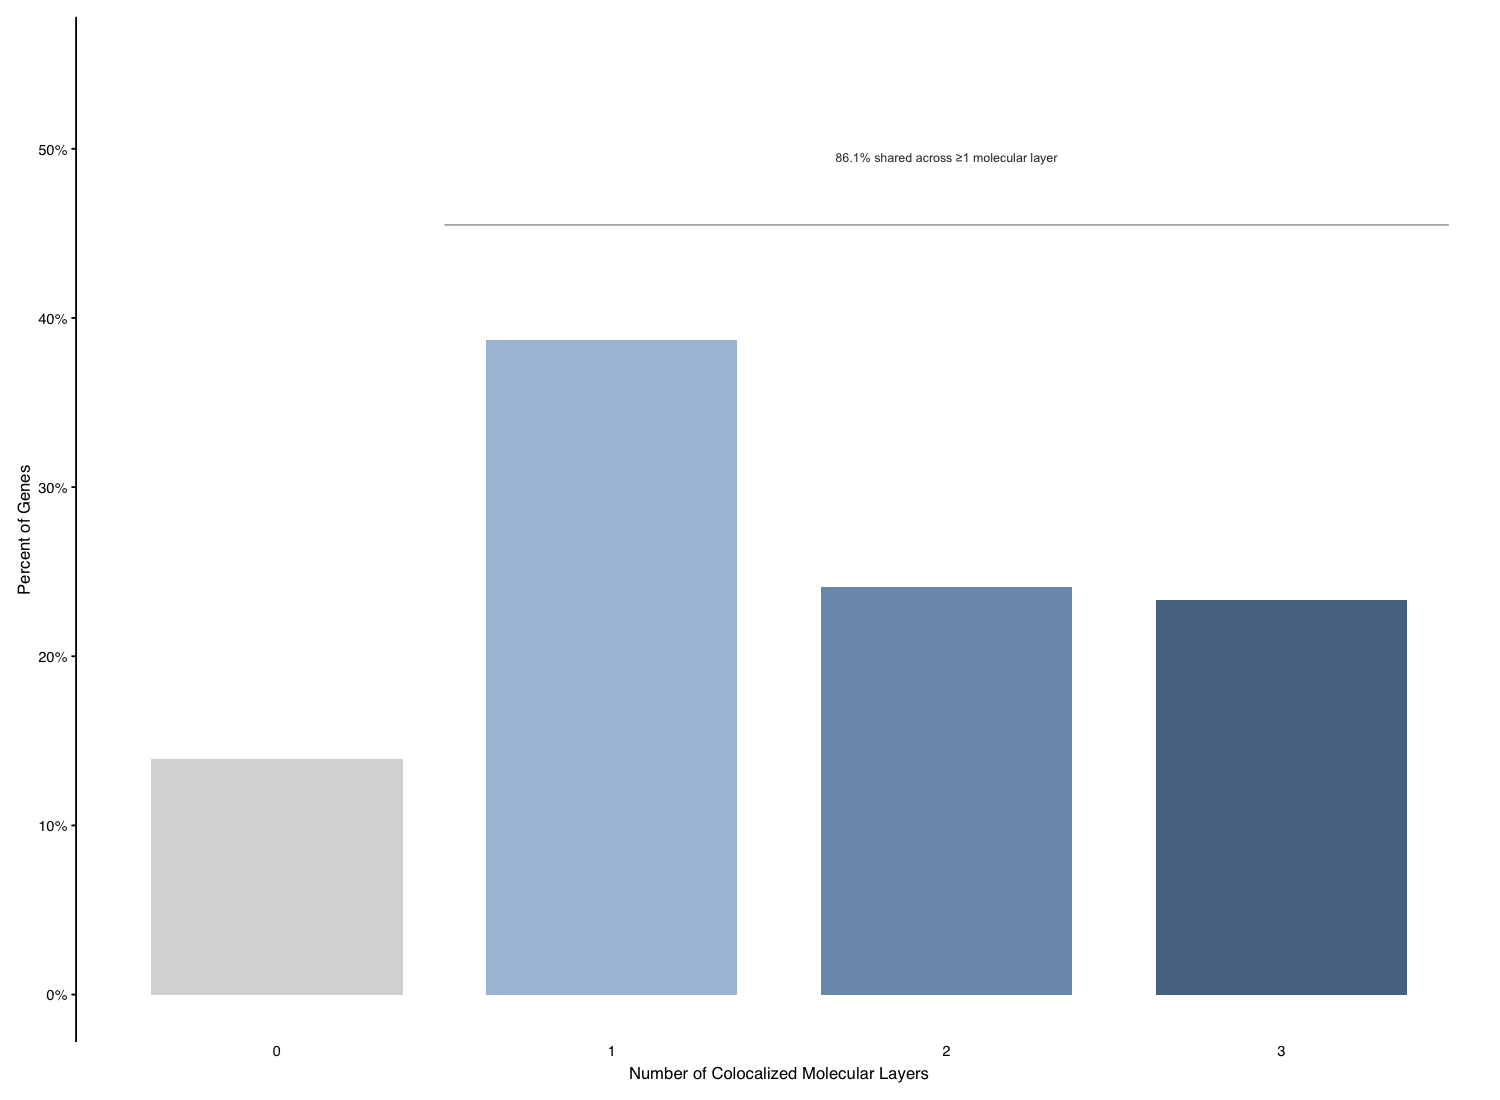

In [3]:
stopifnot(sum(panels$A$data$n) == 755L)
save_plot(panels$A, "Fig3/panel_A", 130, 90)
print(panels$A)


## Colocalized signal components

The saved patchwork includes the signal-count distribution and the per-assay
credible-set inset. The inset is distinct from the assay-pair rates in S22.


Export aggregate plot: Fig3/panel_B


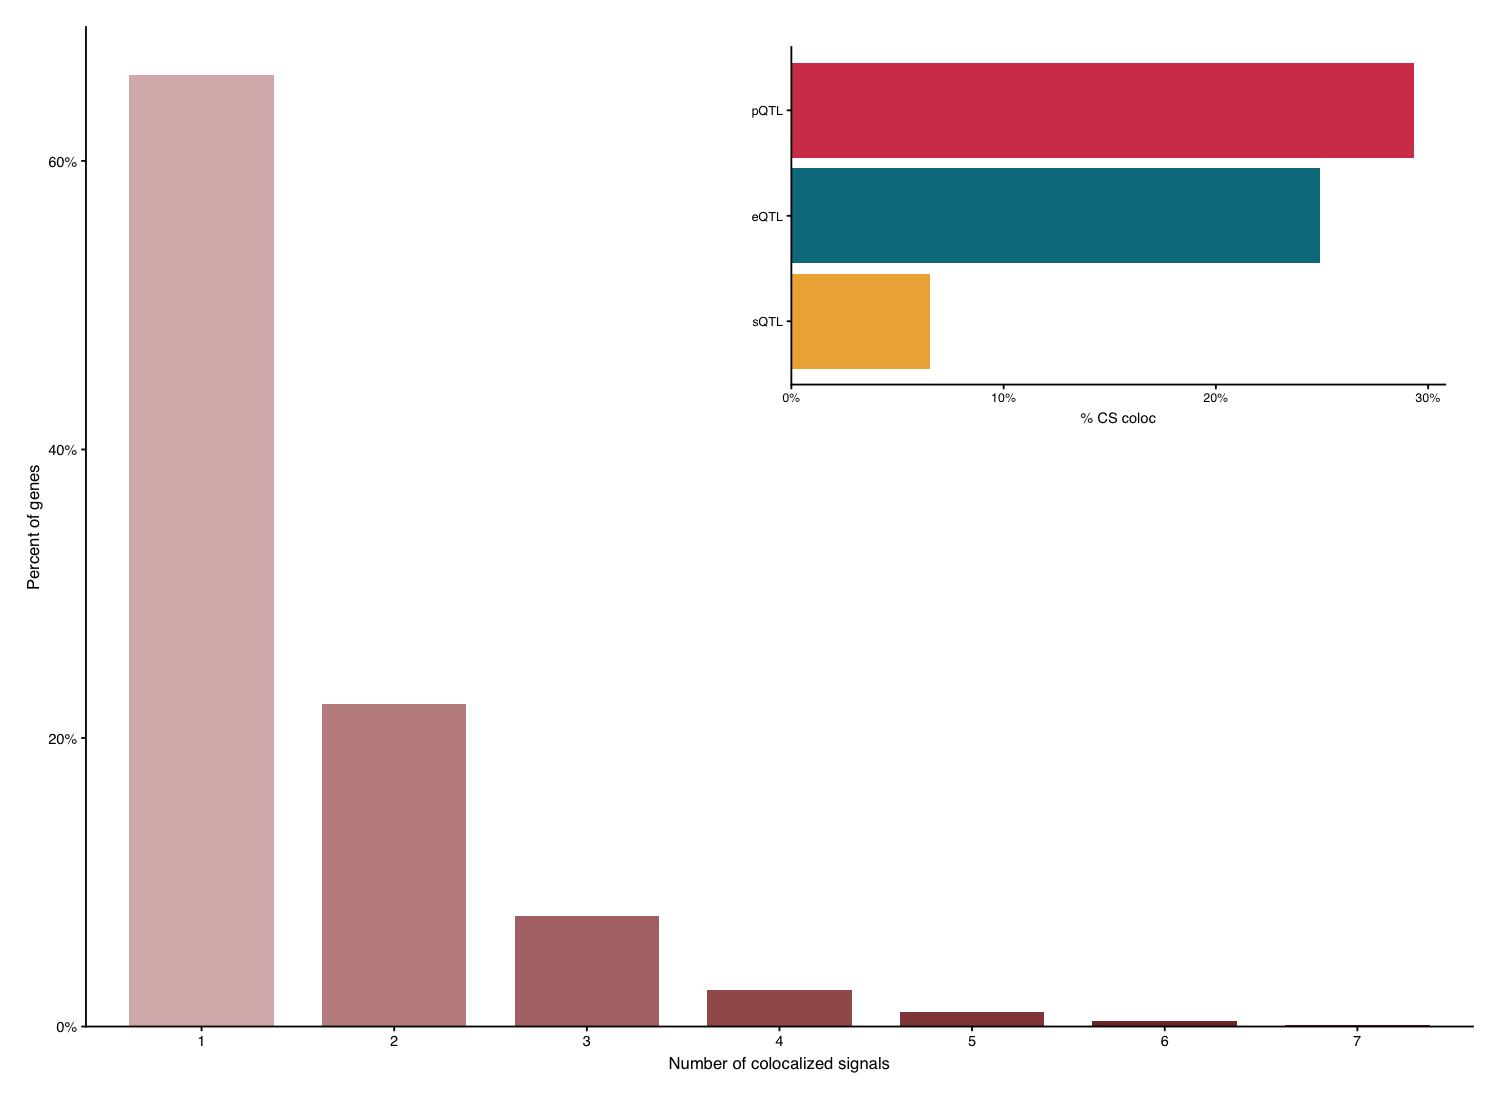

In [4]:
components <- readRDS(source_file("Fig3/data/coloc_cs_components.rds"))
signal_counts <- components |>
  filter(!is.na(coloc_component)) |>
  distinct(Gene, coloc_component) |>
  count(Gene) |>
  count(n, name = "n_genes") |>
  mutate(proportion = n_genes / sum(n_genes))
stopifnot(abs(sum(signal_counts$proportion) - 1) < 1e-12)
genes <- readRDS(source_file("Fig3/data/susie_finemapping.rds"))$genes_all_three_assays
rates <- components |> filter(Gene %in% genes) |> group_by(type) |>
  summarise(n_cs = n_distinct(cs_id), n_coloc = n_distinct(cs_id[has_coloc]),
            coloc_rate = n_coloc / n_cs, .groups = "drop")
# Compare both rebuilt summaries with the exact saved panel before restyling it.
saved_b <- attr(panels$B, "grobs")$full
stopifnot(isTRUE(all.equal(rates, saved_b$data, check.attributes = FALSE)),
          isTRUE(all.equal(signal_counts |> select(n, nn = n_genes),
                           saved_b$patches$plots[[1]]$data, check.attributes = FALSE)))
main <- ggplot(signal_counts, aes(factor(n), proportion, fill = factor(n))) +
  geom_col(width = 0.75) +
  scale_fill_manual(values = c("#D8B7B7", "#C28F8F", "#B17373", "#A25B5B",
                               "#914747", "#803535", "#702626"), guide = "none") +
  scale_y_continuous(labels = scales::label_percent(), expand = expansion(mult = c(0, .05))) +
  labs(x = "Number of colocalized signals", y = "Percent of genes") + notebook_theme
inset <- ggplot(rates, aes(coloc_rate, reorder(type, coloc_rate), fill = type)) +
  geom_col(show.legend = FALSE) +
  scale_fill_manual(values = c(eQTL = "#007C8D", pQTL = "#D44258", sQTL = "#EFB144")) +
  scale_x_continuous(labels = scales::label_percent(), expand = expansion(mult = c(0, .05))) +
  labs(x = "% CS coloc", y = NULL) + notebook_theme +
  theme(axis.text = element_text(size = 6), axis.title = element_text(size = 7),
        plot.margin = margin(0, 0, 0, 0))
panels$B <- wrap_elements(full = main + inset_element(
  inset, left = .48, bottom = .60, right = .98, top = .98, ignore_tag = TRUE))
save_plot(panels$B, "Fig3/panel_B", 150, 100)
print(panels$B)


## Effect-size concordance and allele frequency

Panel C uses the saved interaction coefficients and 95% confidence limits.
Panel D uses the saved transformed expression and protein effects by MAF.
These are the recorded models; no new model specification is substituted.


Export aggregate plot: Fig3/panel_C


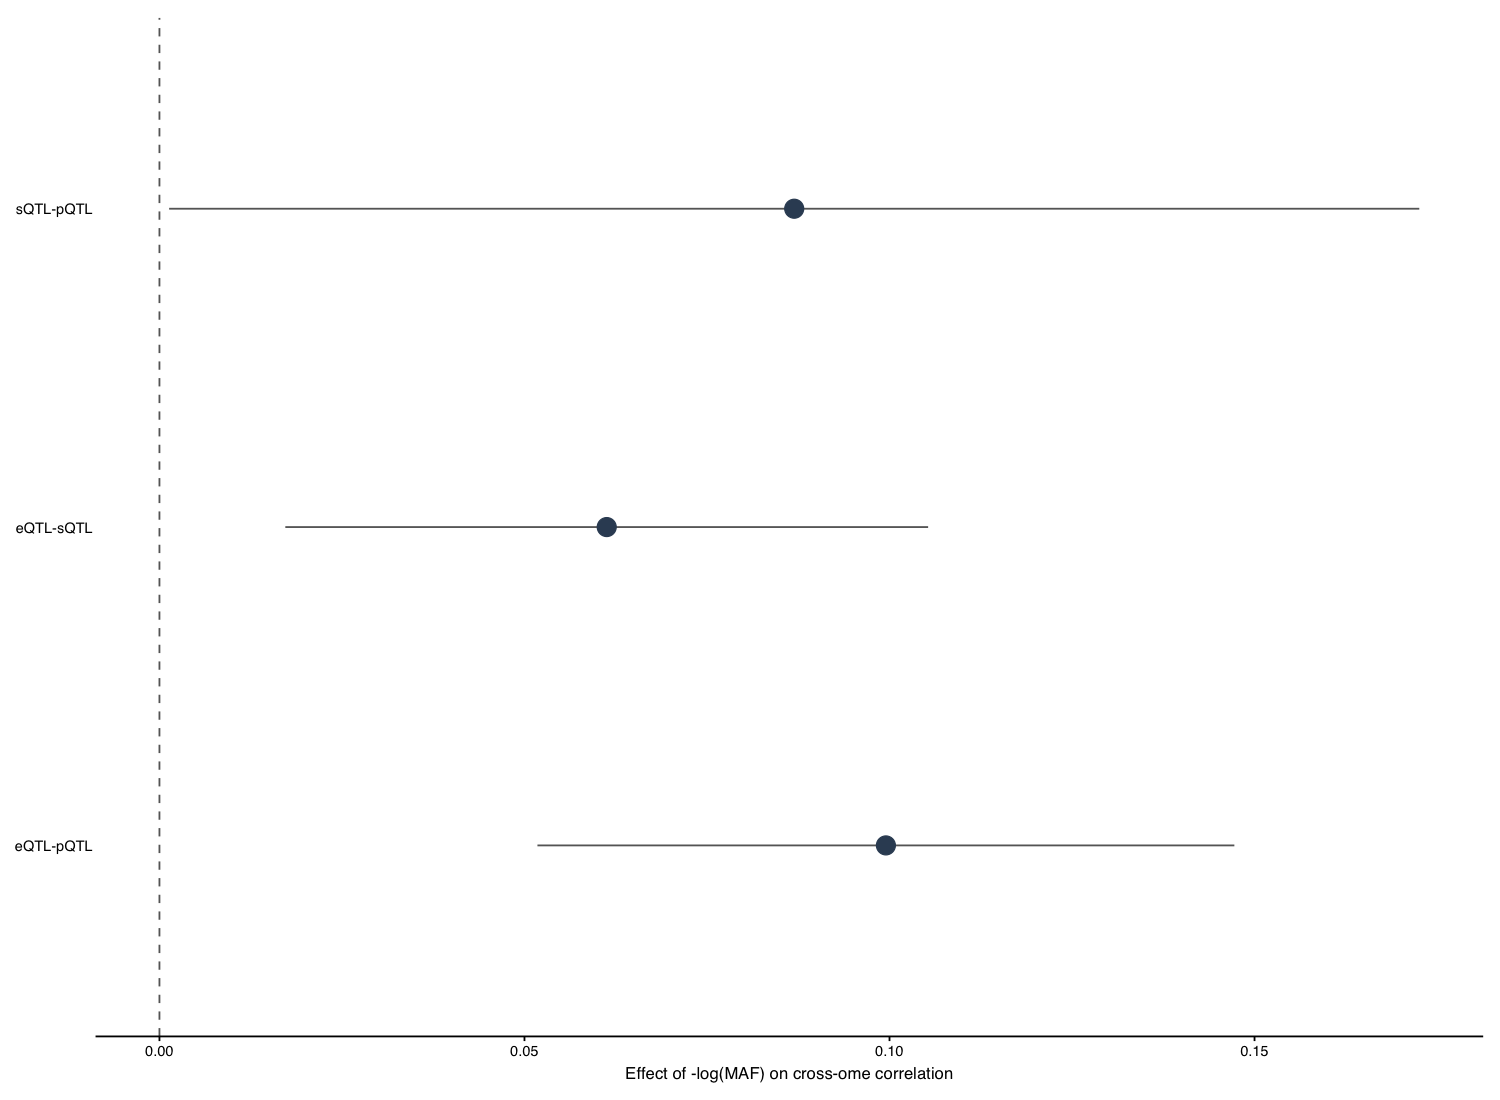

Export aggregate plot: Fig3/panel_D


(`stat_smooth()`).

(`geom_point()`).

(`stat_smooth()`).

(`geom_point()`).

(`stat_smooth()`).

(`geom_point()`).

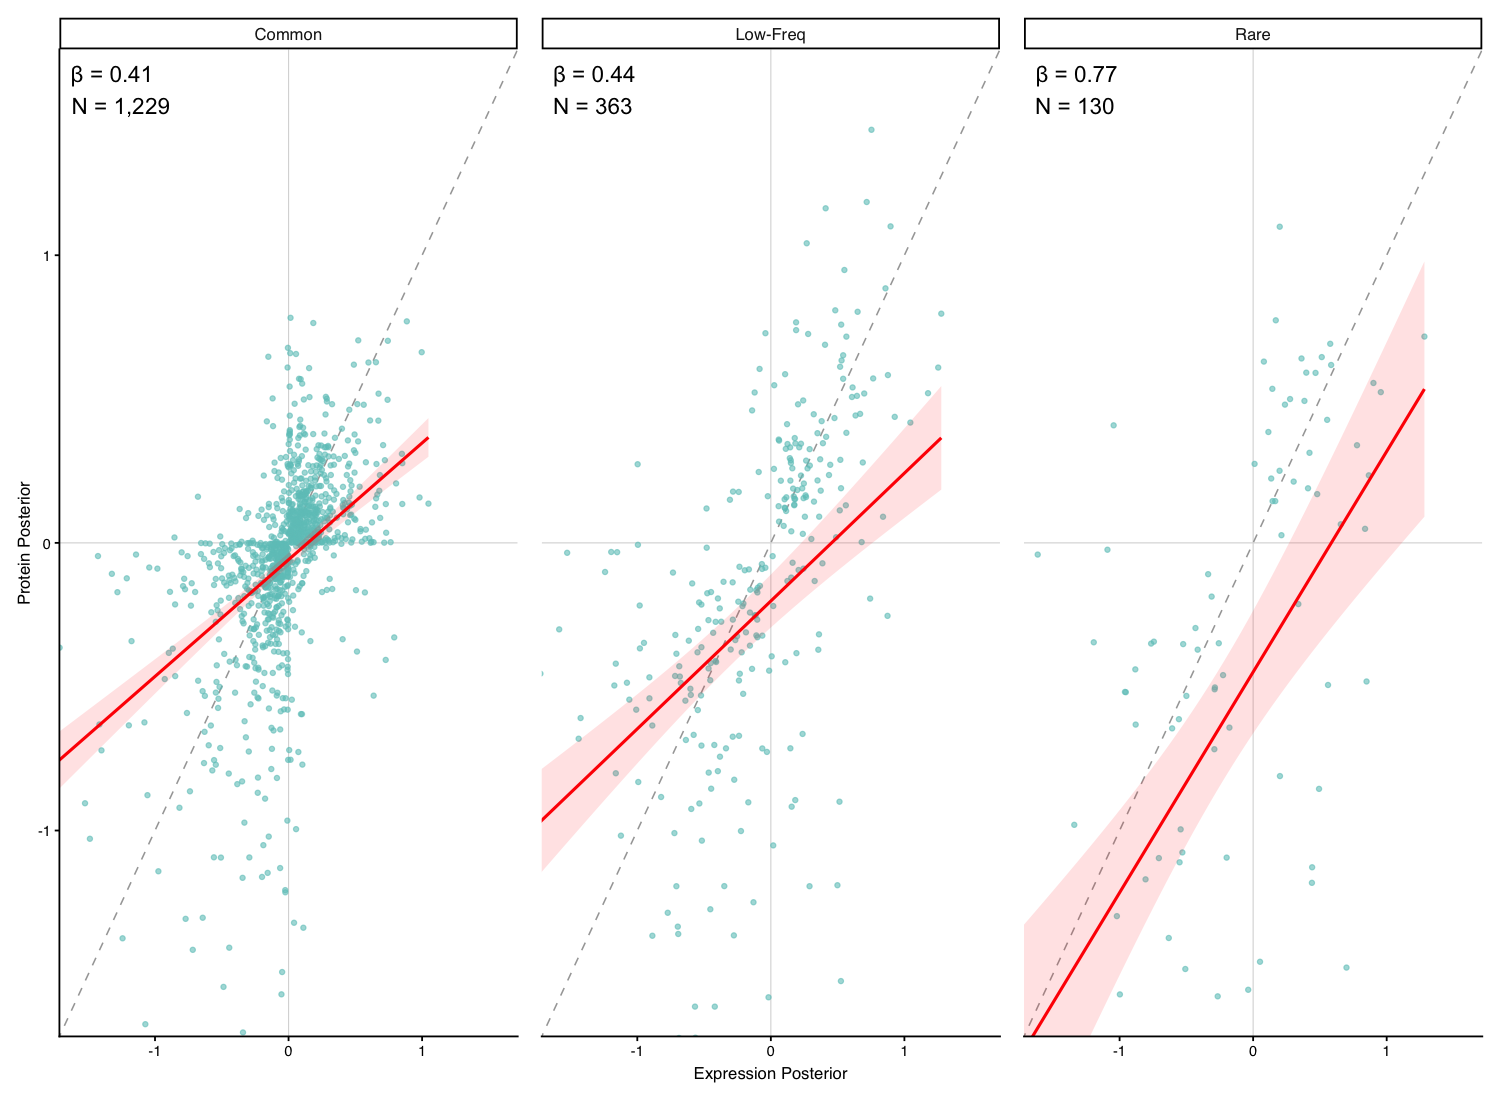

In [5]:
stopifnot(nrow(panels$C$data) == 3L, nrow(panels$D$data) == 1722L)
save_plot(panels$C, "Fig3/panel_C", 140, 100)
print(panels$C)
save_plot(panels$D, "Fig3/panel_D", 180, 100)
print(panels$D)


## Variant annotations

Panel E contains the current annotation results. It is no longer the blank
placeholder described by the original assembly-script comment.


Export aggregate plot: Fig3/panel_E


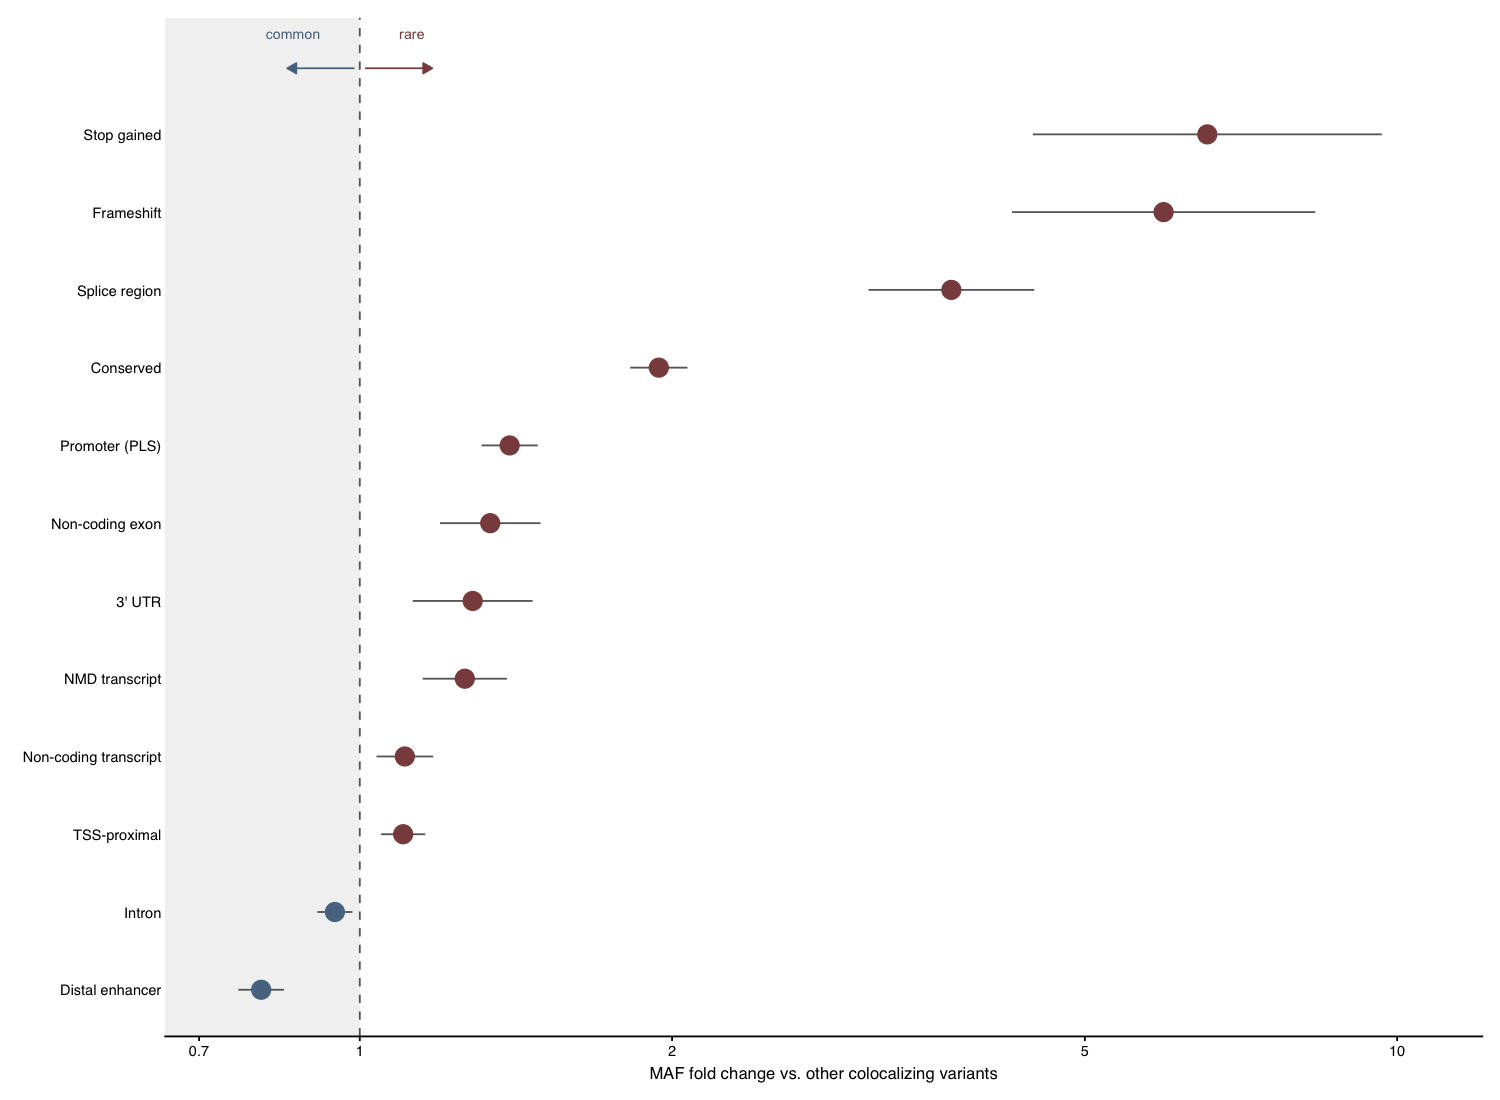

In [6]:
stopifnot(nrow(panels$E$data) > 0L)
save_plot(panels$E, "Fig3/panel_E", 150, 100)
print(panels$E)


## Assemble the current five panels

Keep the current panel order. The exact manuscript image below also contains
the final vector lettering and the archived export resolution.


Export aggregate plot: Fig3/Figure3_rebuilt


(`stat_smooth()`).

(`geom_point()`).

Please use `theme()` to construct themes.

(`stat_smooth()`).

(`geom_point()`).

Please use `theme()` to construct themes.

(`stat_smooth()`).

(`geom_point()`).

Please use `theme()` to construct themes.

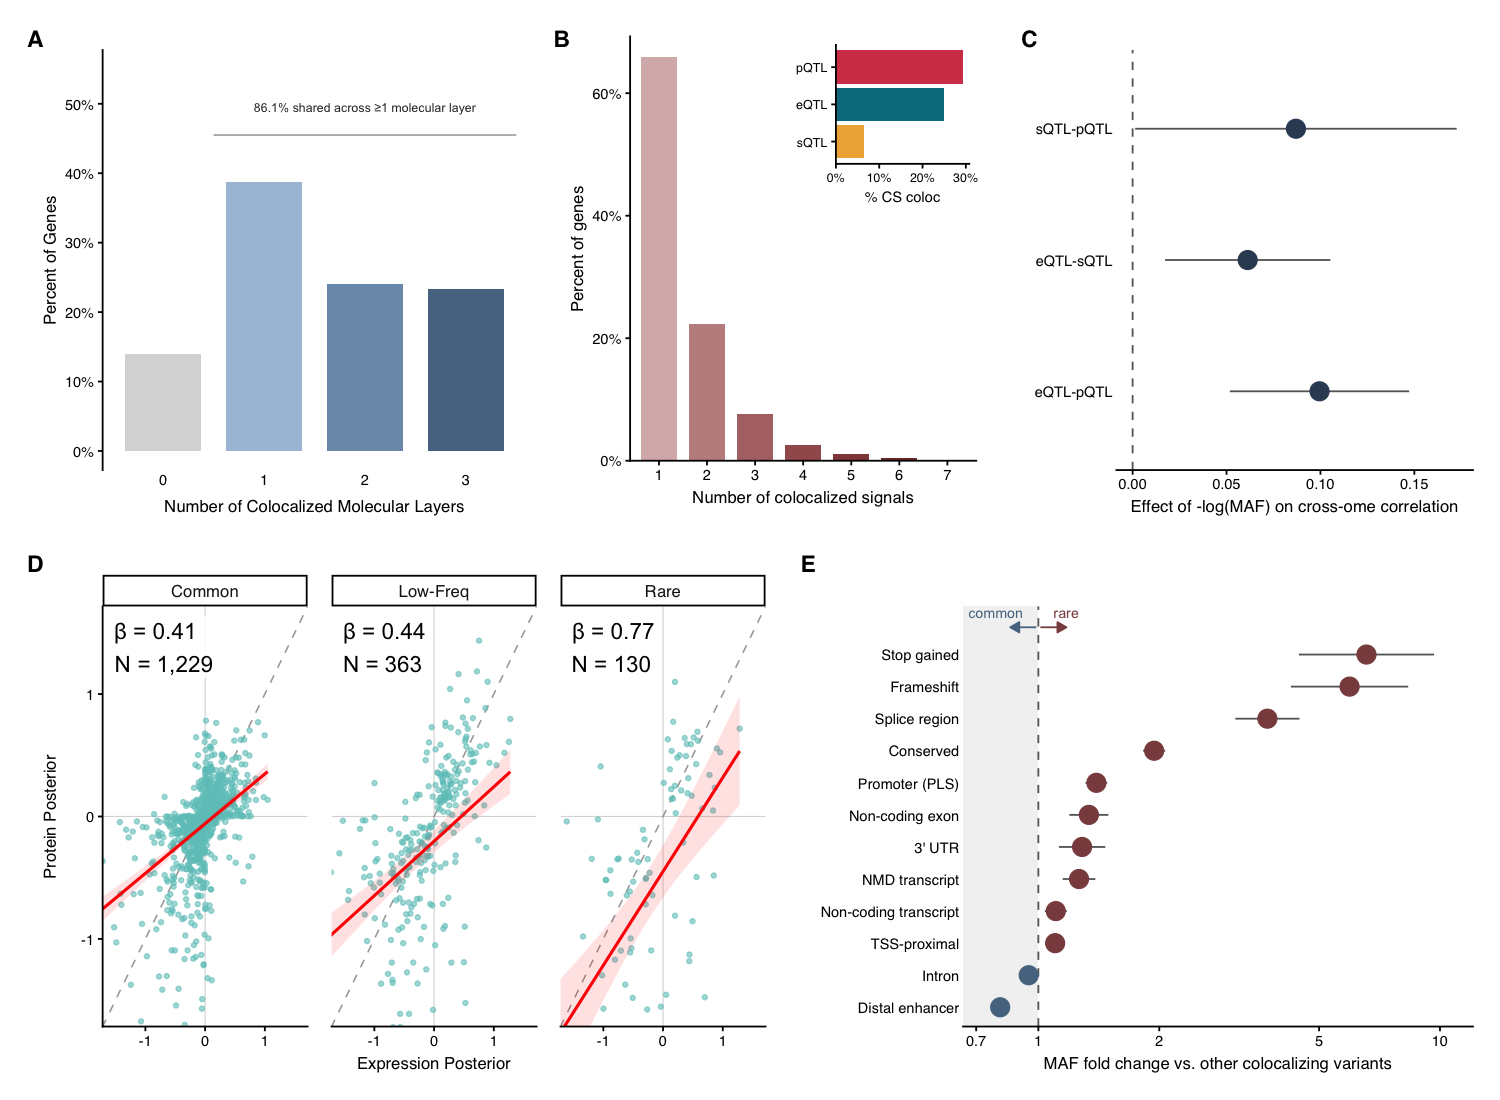

In [7]:
coloc_counts <- panels$A + panels$B + plot_layout(widths = c(1, 1))
top_row <- (coloc_counts | panels$C) + plot_layout(widths = c(2.5, 1))
bottom_row <- (panels$D | panels$E) + plot_layout(widths = c(1.3, 1))
fig3 <- (top_row / bottom_row) + plot_annotation(tag_levels = "A") &
  theme(plot.tag = element_text(size = 11, face = "bold"))
save_plot(fig3, "Fig3/Figure3_rebuilt", 184, 130)
print(fig3)


## Reference figure

Complete figure layout.


Display reference Figure 3.


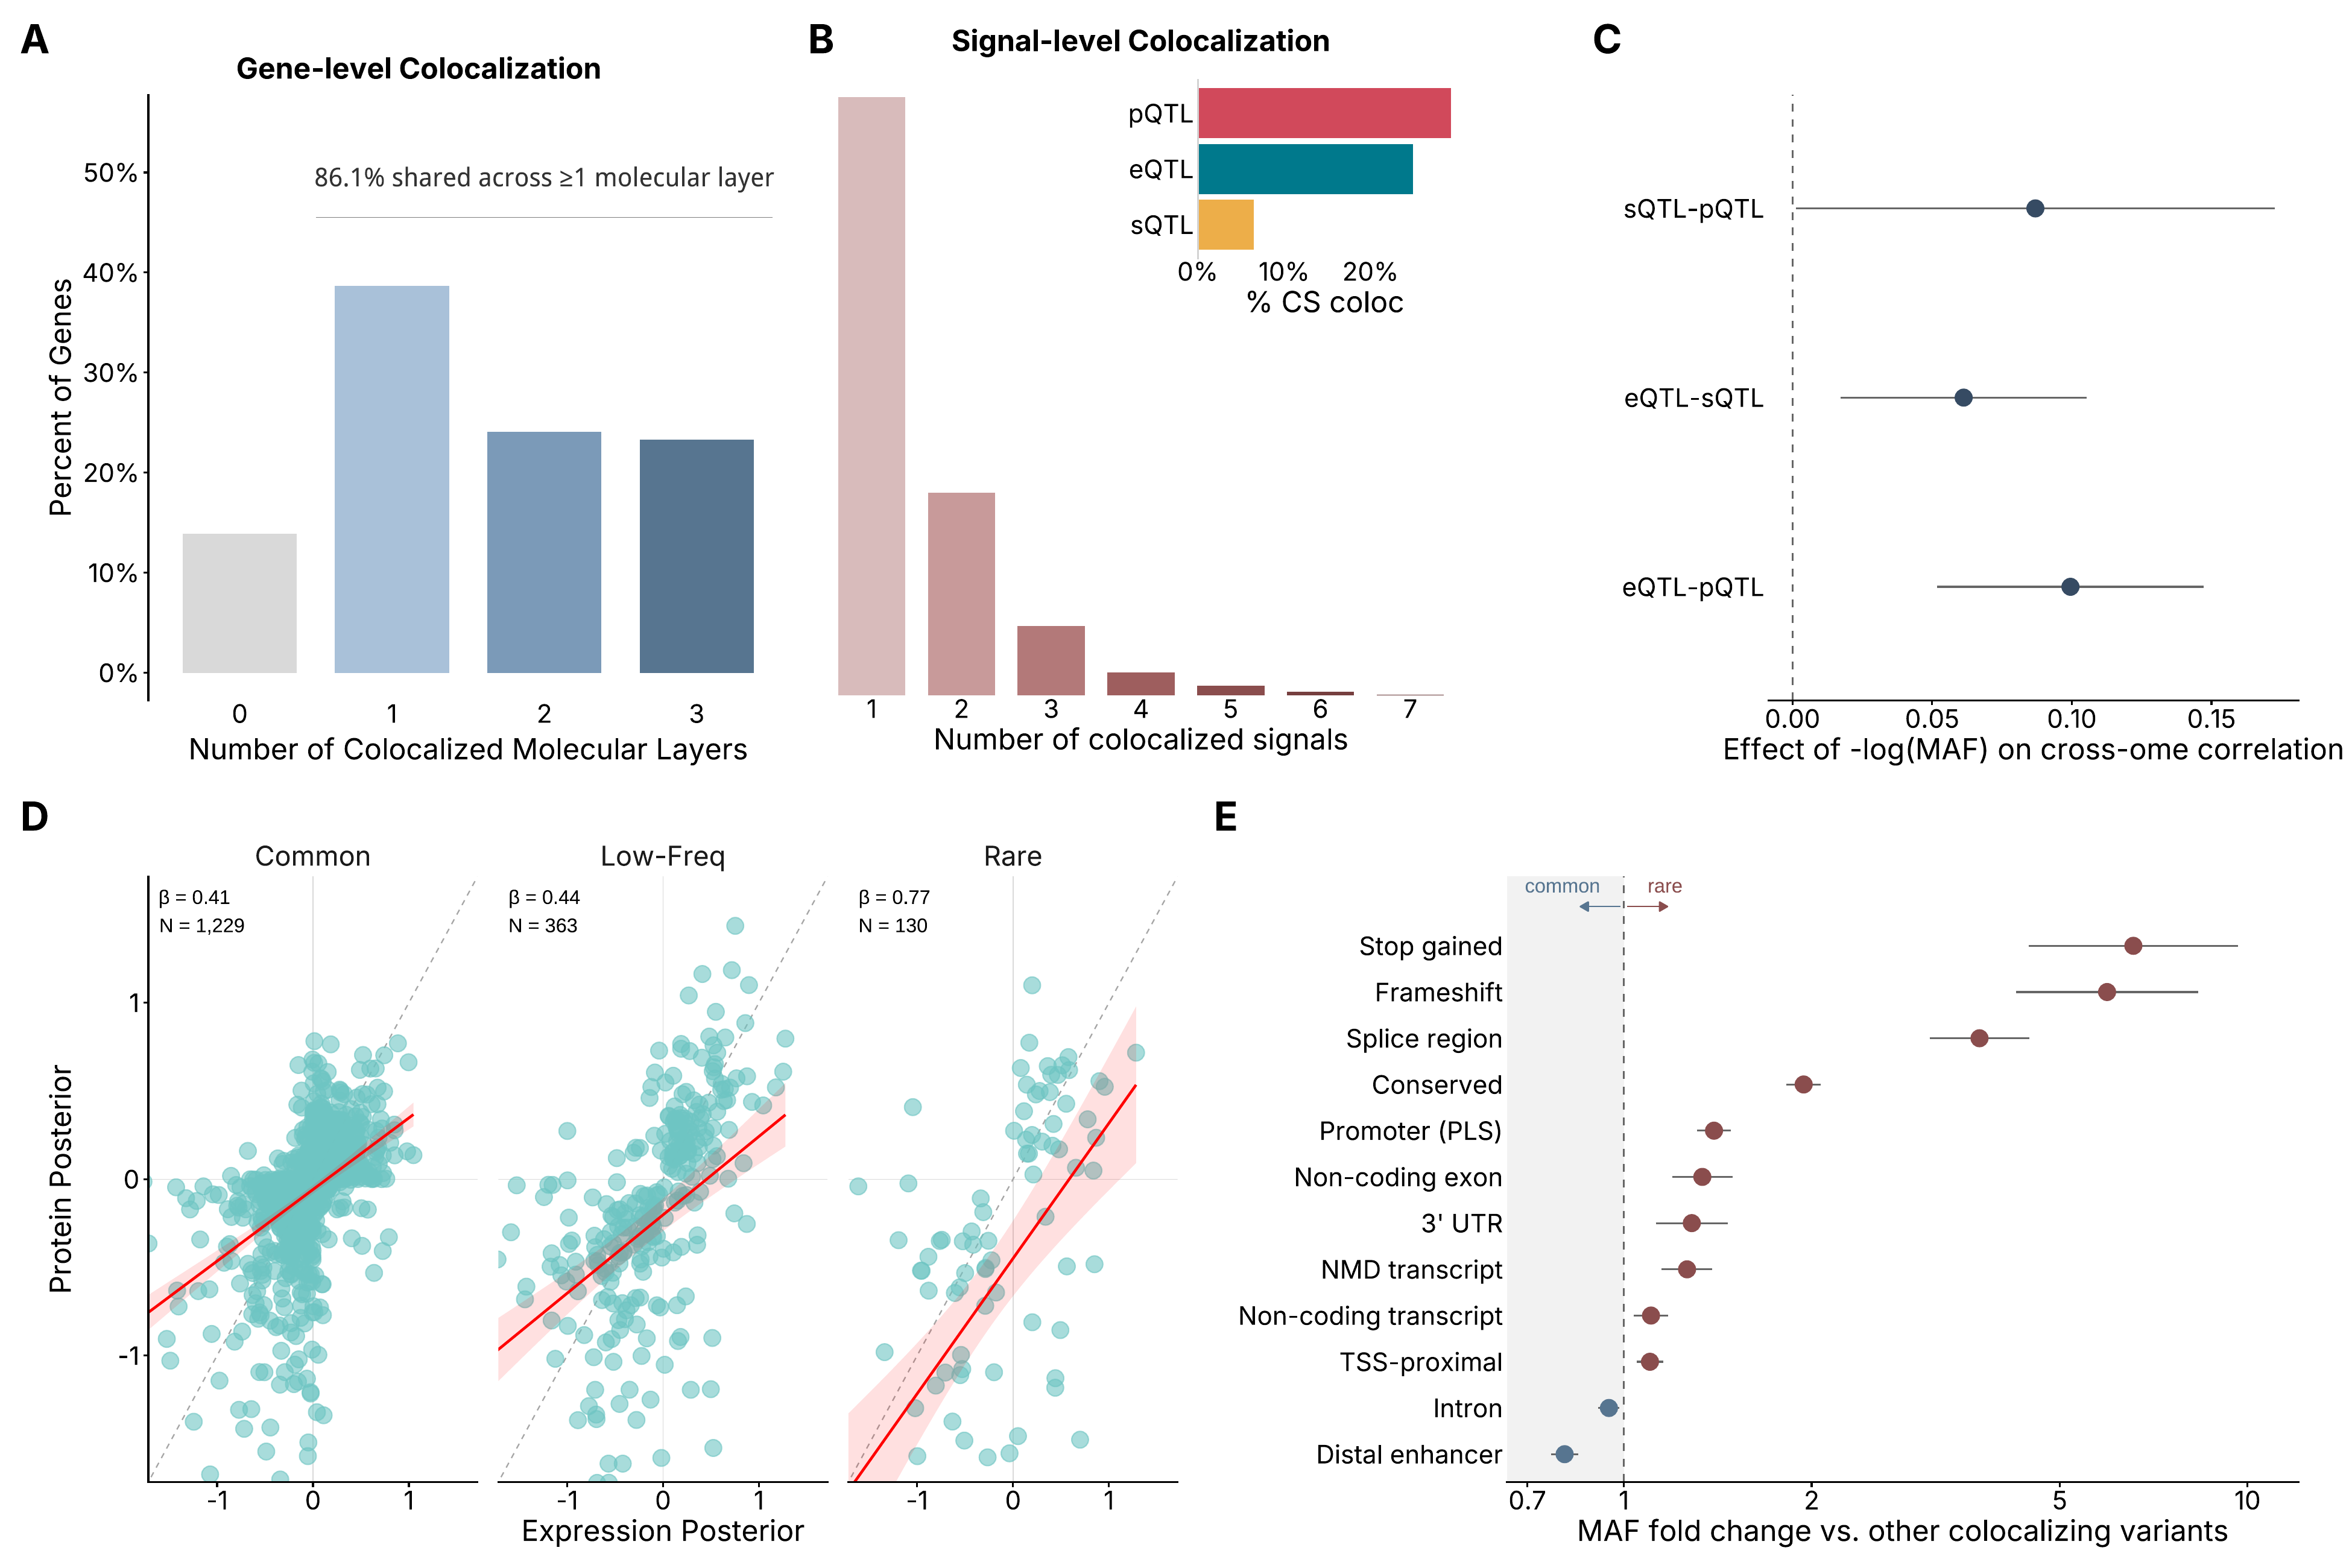

In [8]:
show_reference(3)
